In [5]:
import os
from pathlib import Path

DATA_DIR = Path("../data/raw/classification/PlantVillage/train")
VAL_DIR = Path("../data/raw/classification/PlantVillage/val")

classes = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
val_classes = sorted([d.name for d in VAL_DIR.iterdir() if d.is_dir()])

print(f"Classes in train: {len(classes)}")
print(f"Classes in val:   {len(val_classes)}")
assert classes == val_classes, "Train and val class sets don't match!"
print("Confirmed: train and val agree on all class names.")

Classes in train: 38
Classes in val:   38
Confirmed: train and val agree on all class names.


In [6]:
import pandas as pd

counts = {c: len(list((DATA_DIR / c).glob("*"))) for c in classes}
df = pd.DataFrame(list(counts.items()), columns=["class", "count"]).sort_values("count", ascending=False)
df

,class,count
15,Orange___Haunglongbing_(Citrus_greening),4405
35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,4286
24,Soybean___healthy,4072
16,Peach___Bacterial_spot,1838
28,Tomato___Bacterial_spot,1702
30,Tomato___Late_blight,1527
25,Squash___Powdery_mildew,1468
32,Tomato___Septoria_leaf_spot,1417
33,Tomato___Spider_mites Two-spotted_spider_mite,1341
3,Apple___healthy,1316


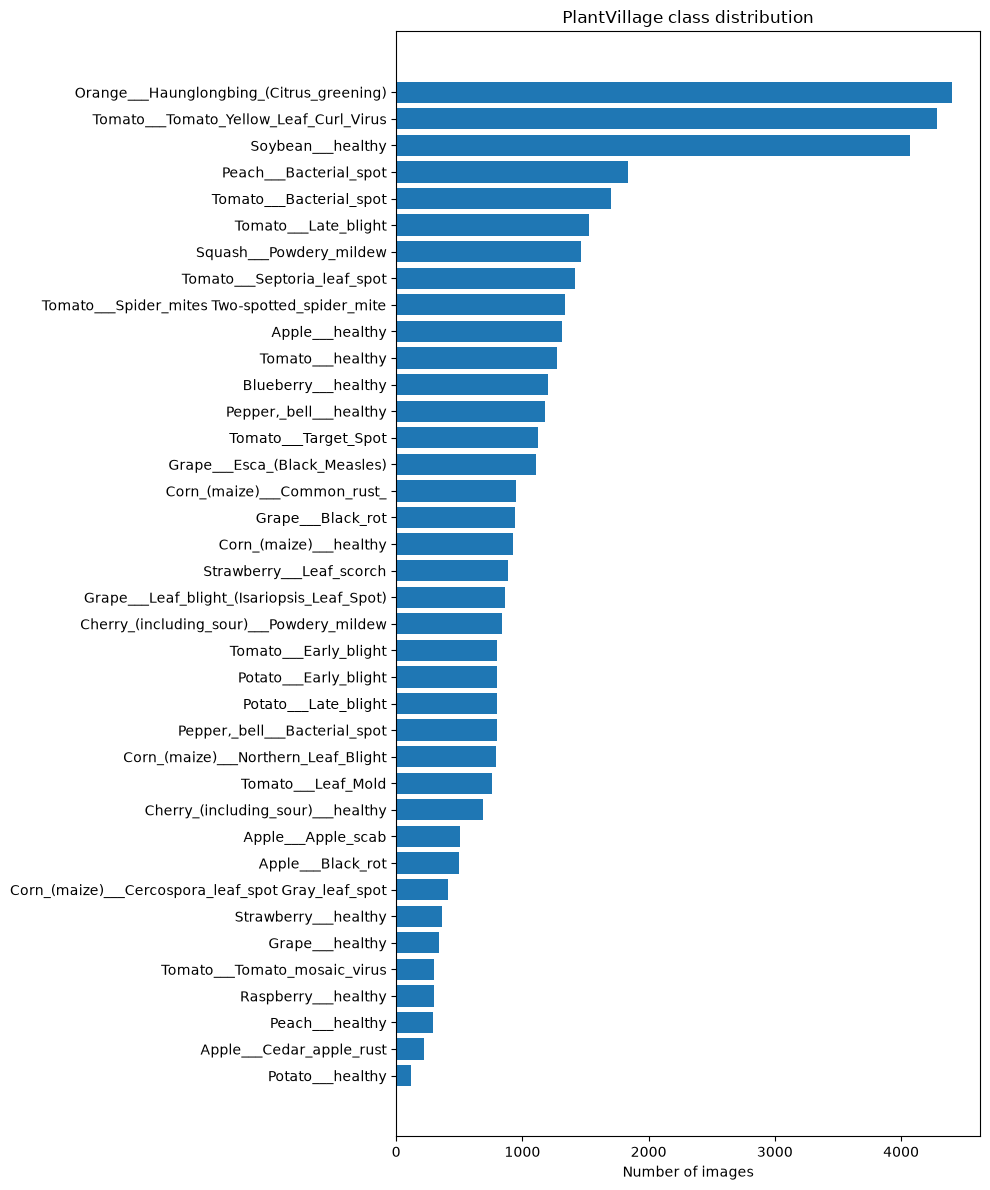

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 12))
plt.barh(df["class"], df["count"])
plt.xlabel("Number of images")
plt.title("PlantVillage class distribution")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

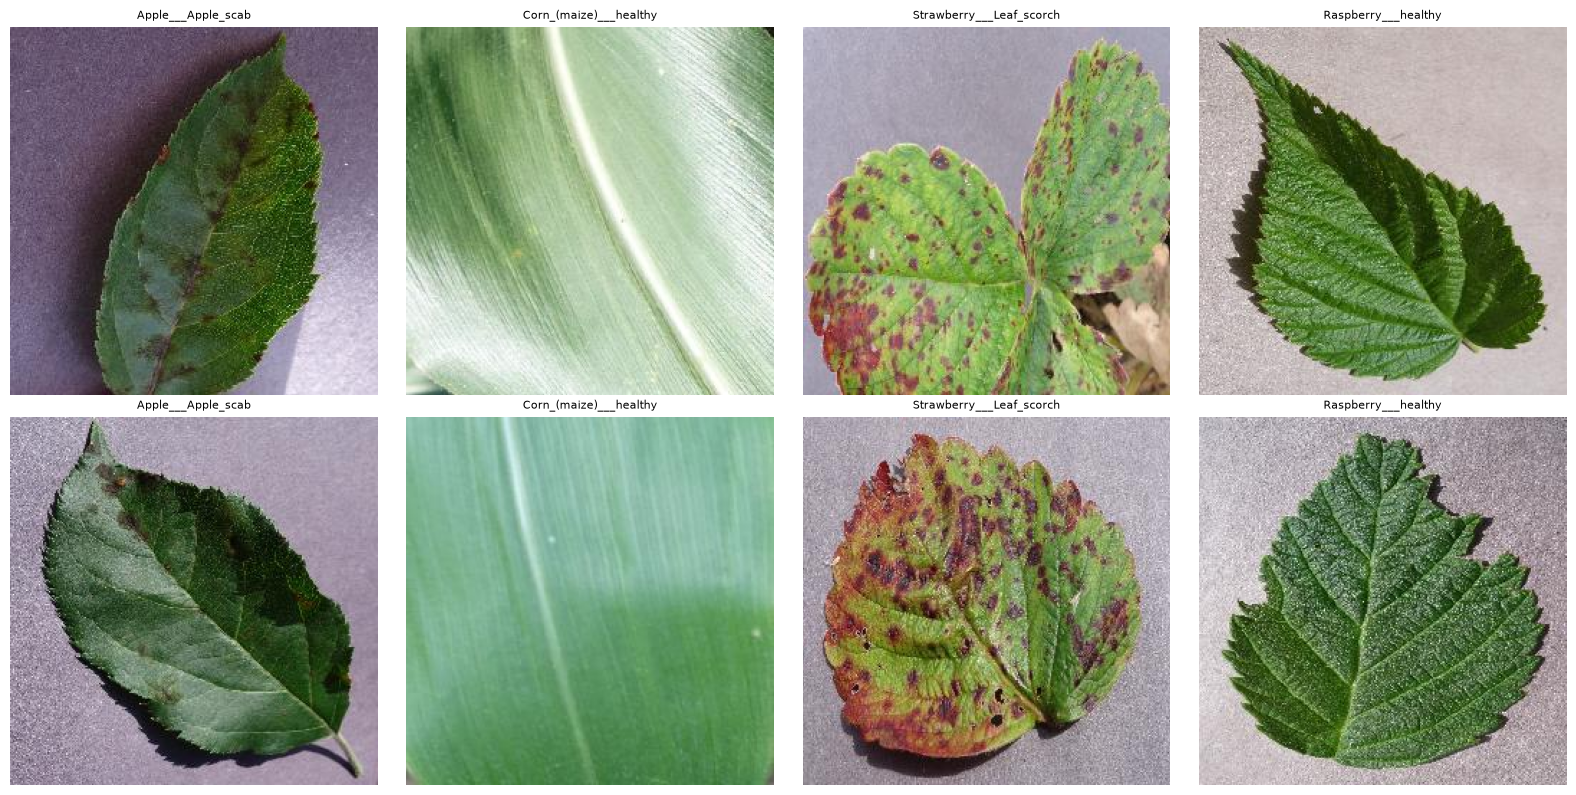

In [8]:
import random
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
sample_classes = random.sample(classes, 4)

for i, cls in enumerate(sample_classes):
    img_files = list((DATA_DIR / cls).glob("*"))
    sample_imgs = random.sample(img_files, 2)
    for j, img_path in enumerate(sample_imgs):
        img = Image.open(img_path)
        axes[j, i].imshow(img)
        axes[j, i].set_title(cls, fontsize=8)
        axes[j, i].axis("off")

plt.tight_layout()
plt.show()

Images: 588, Masks: 588


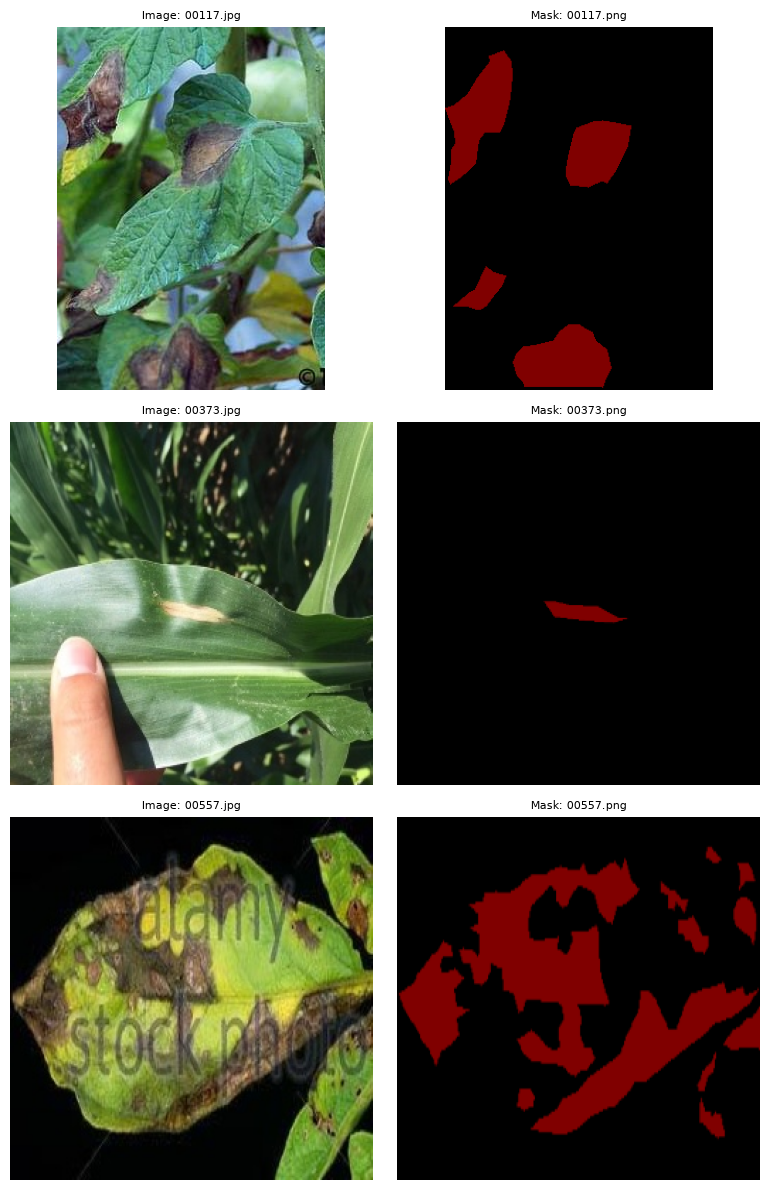

In [9]:
SEG_IMG_DIR = Path("../data/raw/segmentation/data/data/images")
SEG_MASK_DIR = Path("../data/raw/segmentation/data/data/masks")

img_files = sorted(SEG_IMG_DIR.glob("*"))
mask_files = sorted(SEG_MASK_DIR.glob("*"))

print(f"Images: {len(img_files)}, Masks: {len(mask_files)}")

fig, axes = plt.subplots(3, 2, figsize=(8, 12))
sample_ids = random.sample(range(len(img_files)), 3)

for row, idx in enumerate(sample_ids):
    img = Image.open(img_files[idx])
    mask = Image.open(mask_files[idx])
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Image: {img_files[idx].name}", fontsize=8)
    axes[row, 0].axis("off")
    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(f"Mask: {mask_files[idx].name}", fontsize=8)
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()